# Review Sentiment Analysis — NLP Pipeline with TF-IDF and Naive Bayes

**DecodeLabs Data Science Internship · Project 4**

Classify product reviews as **Positive** or **Negative** from their text alone.

**Pipeline:** Ingest → Pre-process (normalize, tokenize, negation-aware stop-words, POS-guided
lemmatization) → Vectorize (TF-IDF, unigrams + bigrams, sparse CSR) → Model (Naive Bayes, compared
with a linear SVM) → Evaluate → Explain



## 1. Setup

In [38]:
import html
import json
import os
import re
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "raw" / "Reviews.csv"
CACHE_PATH = ROOT / "data" / "processed" / "reviews_preprocessed.csv"
FIG_DIR = ROOT / "reports" / "figures"
MODEL_DIR = ROOT / "models"
for folder in (CACHE_PATH.parent, FIG_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
N_JOBS = max(1, (os.cpu_count() or 2) - 1)   # CPU cores used for text pre-processing
BLUE, RED, GREY = "#2a78d6", "#e34948", "#9ca3af"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.dpi": 100})

print("Data file found:", DATA_PATH.exists())
print(f"pandas {pd.__version__} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"scikit-learn {sklearn.__version__} | nltk {nltk.__version__}")
print("CPU cores used for pre-processing:", N_JOBS)

Data file found: True
pandas 3.1.1 | numpy 2.5.5 | scipy 1.18.1 | scikit-learn 1.9.1 | nltk 3.10.4
CPU cores used for pre-processing: 7


### 1.1 NLTK language resources

| Resource | Used for |
|---|---|
| `punkt_tab` | word tokenization |
| `averaged_perceptron_tagger_eng` | part-of-speech (POS) tagging |
| `wordnet` | lemmatization |
| `stopwords` | standard English stop-word list |

Each resource is downloaded only if it is not already installed.

In [39]:
NLTK_RESOURCES = {
    "punkt_tab": "tokenizers/punkt_tab",
    "averaged_perceptron_tagger_eng": "taggers/averaged_perceptron_tagger_eng",
    "wordnet": "corpora/wordnet",
    "stopwords": "corpora/stopwords",
}
def nltk_resource_installed(path):
    # NLTK can read a resource from its folder or directly from the downloaded .zip
    for candidate in (path, f"{path}.zip"):
        try:
            nltk.data.find(candidate)
            return True
        except LookupError:
            pass
    return False


for name, path in NLTK_RESOURCES.items():
    if not nltk_resource_installed(path):
        nltk.download(name, quiet=True)
    assert nltk_resource_installed(path), f"NLTK resource '{name}' could not be downloaded"

from nltk.stem import WordNetLemmatizer
assert WordNetLemmatizer().lemmatize("went", "v") == "go", "WordNet is installed but not working"
print("NLTK resources ready:", ", ".join(NLTK_RESOURCES))

NLTK resources ready: punkt_tab, averaged_perceptron_tagger_eng, wordnet, stopwords


## 2. Ingest the data

The raw file is only read, never modified. Required columns are checked before any processing.

In [40]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"{DATA_PATH} not found - see data/raw/README.md")

raw = pd.read_csv(DATA_PATH)
REQUIRED = {"Id", "ProductId", "UserId", "Score", "Time", "Summary", "Text"}
missing_cols = REQUIRED - set(raw.columns)
assert not missing_cols, f"Missing columns: {missing_cols}"

print(f"Reviews: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Reviews: 568,454 | Columns: 10


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


### 2.1 Column overview

In [41]:
pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "unique_values": raw.nunique(),
})

,dtype,non_null,missing,unique_values
Id,int64,568454,0,568454
ProductId,str,568454,0,74258
UserId,str,568454,0,256059
ProfileName,str,568428,26,218415
HelpfulnessNumerator,int64,568454,0,231
HelpfulnessDenominator,int64,568454,0,234
Score,int64,568454,0,5
Time,int64,568454,0,3168
Summary,str,568427,27,295742
Text,str,568454,0,393579


## 3. Data-quality checks

### 3.1 Star-rating distribution

In [42]:
score_counts = raw["Score"].value_counts().sort_index()
pd.DataFrame({"reviews": score_counts, "share (%)": (score_counts / len(raw) * 100).round(2)})

,reviews,share (%)
Score,,
1,52268,9.19
2,29769,5.24
3,42640,7.50
4,80655,14.19
5,363122,63.88


### 3.2 Empty and duplicate review texts

The same review can appear several times in this dataset (for example when it is listed under
several variants of one product). Duplicate texts must be removed before splitting into train and
test sets; otherwise the model is tested on reviews it has already seen.

In [43]:
text = raw["Text"]
empty_text = text.isna() | (text.fillna("").str.strip() == "")
dup_text = raw.loc[~empty_text].duplicated(subset="Text")

print(f"Missing or empty Text:            {int(empty_text.sum()):,}")
print(f"Exact duplicate rows:             {int(raw.duplicated().sum()):,}")
print(f"Duplicate review texts:           {int(dup_text.sum()):,} "
      f"({dup_text.mean() * 100:.1f}% of non-empty reviews)")
print(f"Reviews with a duplicate in Text but another Score: "
      f"{int((raw.loc[~empty_text].groupby('Text')['Score'].transform('nunique') > 1).sum()):,}")

Missing or empty Text:            0
Exact duplicate rows:             0
Duplicate review texts:           174,875 (30.8% of non-empty reviews)
Reviews with a duplicate in Text but another Score: 322


## 4. Labels and cleaning

The dataset has star ratings, not sentiment labels. Labels are derived from the rating:

| Score | Label | Reason |
|---|---|---|
| 4–5 ★ | **Positive (1)** | the customer was satisfied |
| 1–2 ★ | **Negative (0)** | the customer was dissatisfied |
| 3 ★ | removed | neutral or mixed opinion; it fits neither class |

Cleaning order:

1. remove missing or empty texts;
2. remove 3-star reviews;
3. remove texts that occur with **both** labels (contradictory examples);
4. keep one copy of each remaining duplicate text.

In [44]:
df = raw.loc[~empty_text, ["Id", "Score", "Text"]].copy()
n_start = len(df)

df = df[df["Score"] != 3]
n_after_neutral = len(df)

df["label"] = (df["Score"] >= 4).astype(int)
conflicting = df.groupby("Text")["label"].transform("nunique") > 1
df = df[~conflicting]
n_after_conflict = len(df)

df = df.drop_duplicates(subset="Text").reset_index(drop=True)

pd.DataFrame({"reviews": [len(raw), n_start, n_after_neutral, n_after_conflict, len(df)]},
             index=["raw file", "non-empty text", "3-star removed",
                    "contradictory texts removed", "duplicate texts removed (final)"])

,reviews
raw file,568454
non-empty text,568454
3-star removed,525814
contradictory texts removed,525797
duplicate texts removed (final),363831


### 4.1 Class balance

Naive Bayes learns class priors from the training data, so an imbalanced dataset pushes
predictions toward the majority class. This decides which metric is used in section 9.

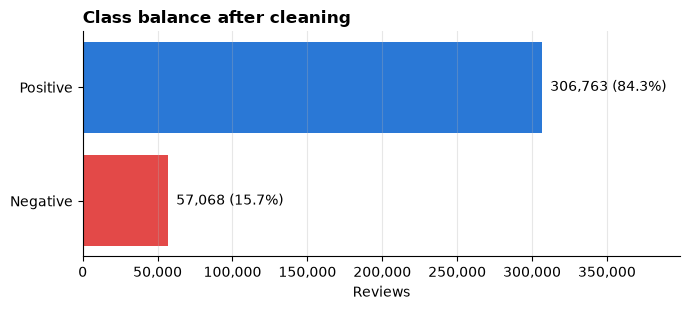

Imbalance ratio (Positive : Negative) = 5.38 : 1


In [45]:
LABEL_NAMES = {0: "Negative", 1: "Positive"}
class_counts = df["label"].value_counts().sort_index()
class_share = class_counts / len(df) * 100

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.barh([LABEL_NAMES[i] for i in class_counts.index], class_counts.values, color=[RED, BLUE])
for bar, n, share in zip(bars, class_counts.values, class_share.values):
    ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, f"  {n:,} ({share:.1f}%)",
            va="center", fontsize=10)
ax.set_xlim(0, class_counts.max() * 1.3)
ax.set_xlabel("Reviews")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Class balance after cleaning", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_class_balance.png", dpi=150)
plt.show()

print(f"Imbalance ratio (Positive : Negative) = {class_counts[1] / class_counts[0]:.2f} : 1")

## 5. Text profile

Length of the reviews and the noise the pre-processing has to handle: HTML line breaks, HTML
entities (`&amp;`), links and negation contractions (`don't`, `isn't`).

In [46]:
words = df["Text"].str.split().str.len()
noise = pd.DataFrame({
    "pattern": [r"<[^>]+>", r"&[a-z]+;|&#\d+;", r"https?://|www\.", r"n't\b"],
}, index=["HTML tags (e.g. <br />)", "HTML entities", "links", "negation contractions"])
noise["reviews (%)"] = [df["Text"].str.contains(p, case=False, regex=True).mean() * 100
                        for p in noise["pattern"]]

display(words.groupby(df["label"].map(LABEL_NAMES)).describe().round(1))
noise[["reviews (%)"]].round(2)

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Negative,57068.0,85.2,78.8,3.0,38.0,63.0,105.0,2149.0
Positive,306763.0,77.1,75.4,3.0,33.0,54.0,94.0,2520.0


,reviews (%)
HTML tags (e.g. <br />),25.54
HTML entities,0.34
links,2.05
negation contractions,32.19


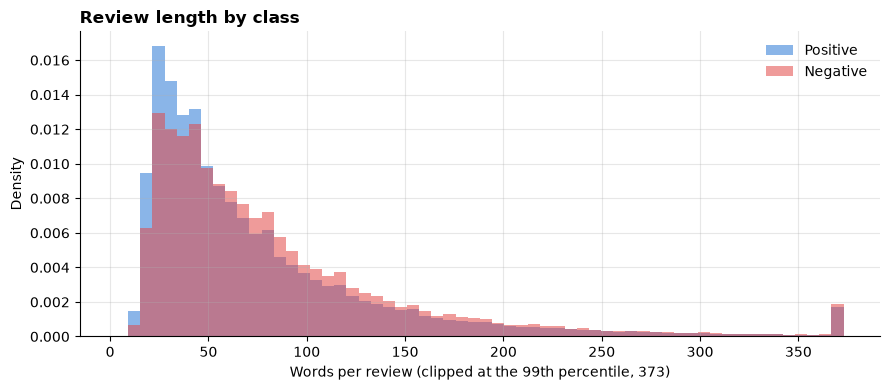

In [47]:
clip = int(words.quantile(0.99))
fig, ax = plt.subplots(figsize=(9, 4))
for label, color in [(1, BLUE), (0, RED)]:
    ax.hist(words[df["label"] == label].clip(upper=clip), bins=60, alpha=0.55, color=color,
            density=True, label=LABEL_NAMES[label])
ax.set_xlabel(f"Words per review (clipped at the 99th percentile, {clip})")
ax.set_ylabel("Density")
ax.set_title("Review length by class", loc="left", fontweight="bold")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_review_length.png", dpi=150)
plt.show()

## 6. Pre-processing

Each step is built and demonstrated separately, then combined into one function in 6.5.

### 6.1 Character normalization

- HTML entities are decoded (`&amp;` → `&`) and HTML tags such as `<br />` are replaced by a space.
- Links are removed.
- Text is lower-cased, so `Good` and `good` become the same token.
- Negation contractions are expanded (`don't` → `do not`, `can't` → `can not`, `won't` →
  `will not`), so that every negation becomes the single token **`not`**.



In [48]:
HTML_TAG = re.compile(r"<[^>]+>")
URL = re.compile(r"https?://\S+|www\.\S+")
CANT = re.compile(r"\b(?:can't|cannot)\b")
WONT = re.compile(r"\bwon't\b")
NT = re.compile(r"n't\b")
SPACES = re.compile(r"\s+")


def normalize_text(text: str) -> str:
    text = html.unescape(text)
    text = HTML_TAG.sub(" ", text)
    text = URL.sub(" ", text)
    text = text.lower().replace("\u2019", "'")          # curly apostrophe -> '
    text = CANT.sub("can not", text)
    text = WONT.sub("will not", text)
    text = NT.sub(" not", text)
    return SPACES.sub(" ", text).strip()


example = df.loc[df["Text"].str.contains("<br", regex=False), "Text"].iloc[0]
print("BEFORE:\n", example[:400], "\n")
print("AFTER:\n", normalize_text(example)[:400])

BEFORE:
 I don't know if it's the cactus or the tequila or just the unique combination of ingredients, but the flavour of this hot sauce makes it one of a kind!  We picked up a bottle once on a trip we were on and brought it back home with us and were totally blown away!  When we realized that we simply couldn't find it anywhere in our city we were bummed.<br /><br />Now, because of the magic of the intern 

AFTER:
 i do not know if it's the cactus or the tequila or just the unique combination of ingredients, but the flavour of this hot sauce makes it one of a kind! we picked up a bottle once on a trip we were on and brought it back home with us and were totally blown away! when we realized that we simply could not find it anywhere in our city we were bummed. now, because of the magic of the internet, we have


### 6.2 Tokenization

NLTK's `word_tokenize` splits text into words and punctuation marks.

In [49]:
from nltk.tokenize import word_tokenize

sample = "I didn't like it. The cookies weren't fresh &amp; the box was crushed!"
print("Normalized:", normalize_text(sample))
print("Tokens:    ", word_tokenize(normalize_text(sample)))

Normalized: i did not like it. the cookies were not fresh & the box was crushed!
Tokens:     ['i', 'did', 'not', 'like', 'it', '.', 'the', 'cookies', 'were', 'not', 'fresh', '&', 'the', 'box', 'was', 'crushed', '!']


### 6.3 Custom stop-word list that keeps negations

Standard stop-word lists contain *not*, *no* and *nor*. Removing them reverses the meaning of a
review: "I am **not** happy" would become "happy". The custom list is built with set operations:

`CUSTOM_STOPWORDS = STANDARD_STOPWORDS − NEGATIONS`

In [50]:
from nltk.corpus import stopwords

STANDARD_STOPWORDS = set(stopwords.words("english"))
NEGATIONS = {"no", "not", "nor", "never", "none", "nothing", "nobody", "neither", "nowhere"}
CUSTOM_STOPWORDS = STANDARD_STOPWORDS - NEGATIONS

print(f"Standard list: {len(STANDARD_STOPWORDS)} words | custom list: {len(CUSTOM_STOPWORDS)} words")
print("Kept because they carry negation:", sorted(STANDARD_STOPWORDS & NEGATIONS))

demo = word_tokenize(normalize_text("I am not happy"))
pd.DataFrame({
    "tokens after removal": [[t for t in demo if t not in STANDARD_STOPWORDS],
                             [t for t in demo if t not in CUSTOM_STOPWORDS]],
}, index=["standard stop-words", "custom stop-words"])

Standard list: 198 words | custom list: 195 words
Kept because they carry negation: ['no', 'nor', 'not']


,tokens after removal
standard stop-words,[happy]
custom stop-words,"[not, happy]"


### 6.4 POS-guided lemmatization

`WordNetLemmatizer` treats every word as a noun unless it is told the part of speech, so *went*
stays *went*. The POS tagger returns Penn Treebank tags (`VBD`, `JJ`, …), which are mapped to the
four WordNet classes:

| Treebank tag starts with | WordNet POS |
|---|---|
| `J` | adjective |
| `V` | verb |
| `N` | noun |
| `R` | adverb |
| anything else | noun (WordNet default) |

Tagging is done on the **full** token sequence, before stop-words and punctuation are removed, so
the tagger sees each word in its real context.

In [51]:
from nltk import pos_tag, pos_tag_sents
from nltk.corpus import wordnet
from nltk.stem import WordNetLemmatizer

TREEBANK_TO_WORDNET = {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}


def to_wordnet_pos(treebank_tag: str) -> str:
    return TREEBANK_TO_WORDNET.get(treebank_tag[:1], "n")      # "n" = wordnet.NOUN


lemmatizer = WordNetLemmatizer()
demo_tokens = word_tokenize("we went there and the dogs were running to better treats")
pd.DataFrame([
    {"token": tok, "Treebank tag": tag, "WordNet POS": to_wordnet_pos(tag),
     "lemma without POS": lemmatizer.lemmatize(tok),
     "lemma with POS": lemmatizer.lemmatize(tok, to_wordnet_pos(tag))}
    for tok, tag in pos_tag(demo_tokens)
])

,token,Treebank tag,WordNet POS,lemma without POS,lemma with POS
0,we,PRP,n,we,we
1,went,VBD,v,went,go
2,there,EX,n,there,there
3,and,CC,n,and,and
4,the,DT,n,the,the
5,dogs,NNS,n,dog,dog
6,were,VBD,v,were,be
7,running,VBG,v,running,run
8,to,TO,n,to,to
9,better,JJR,a,better,good


### 6.5 Complete pre-processing function

`preprocess_batch` applies every step to a list of reviews:

normalize → tokenize → POS-tag → keep alphabetic tokens of 2+ letters that are not in the custom
stop-word list → lemmatize with the mapped POS → join with spaces.

The tagger is loaded once per batch (`pos_tag_sents`) and lemmas are cached, because the same
(word, POS) pairs repeat across many reviews.

In [52]:
def preprocess_batch(texts):
    lemmatizer = WordNetLemmatizer()
    cache = {}
    tokenized = [word_tokenize(normalize_text(t)) for t in texts]
    output = []
    for tagged in pos_tag_sents(tokenized):
        lemmas = []
        for token, tag in tagged:
            if len(token) < 2 or not token.isalpha() or token in CUSTOM_STOPWORDS:
                continue
            key = (token, tag[:1])
            if key not in cache:
                cache[key] = lemmatizer.lemmatize(token, to_wordnet_pos(tag))
            lemmas.append(cache[key])
        output.append(" ".join(lemmas))
    return output


examples = df.groupby("label").sample(2, random_state=RANDOM_STATE)["Text"].tolist()
pd.DataFrame({"original": [t[:160] for t in examples],
              "pre-processed": [t[:160] for t in preprocess_batch(examples)]})

,original,pre-processed
0,There were something like 6 marshmallows in th...,something like marshmallow packet along bitter...
1,They taste more like chemicals than meat. I l...,taste like chemical meat like lot jerky meat s...
2,It doesn't take long to adjust to flax seed ch...,not take long adjust flax seed chip greasy sal...
3,ACHVA HALVA WITH PISTACHIOS: JUST BOUGHT A CAS...,achva halva pistachio buy case amazon not find...


### 6.6 Processing speed

POS tagging is the slowest step. It is timed on 1,000 reviews to estimate the run time for the
full dataset before running it.

In [53]:
timing_sample = df["Text"].sample(min(1_000, len(df)), random_state=RANDOM_STATE).tolist()
start = time.perf_counter()
preprocess_batch(timing_sample)
seconds = time.perf_counter() - start

per_review_ms = seconds / len(timing_sample) * 1000
estimate_min = per_review_ms * len(df) / 1000 / 60
print(f"{len(timing_sample):,} reviews in {seconds:.2f} s ({per_review_ms:.2f} ms per review)")
print(f"Estimated time for {len(df):,} reviews: {estimate_min:.1f} min on 1 core, "
      f"about {estimate_min / N_JOBS:.1f} min on {N_JOBS} cores")

1,000 reviews in 12.42 s (12.42 ms per review)
Estimated time for 363,831 reviews: 75.3 min on 1 core, about 10.8 min on 7 cores


### 6.7 Pre-process every review


In [54]:
from joblib import Parallel, delayed

REBUILD_CACHE = False
CHUNK_SIZE = 5_000

cache_valid = False
if CACHE_PATH.exists() and not REBUILD_CACHE:
    cached = pd.read_csv(CACHE_PATH, keep_default_na=False)
    cache_valid = len(cached) == len(df) and cached["Id"].to_numpy().tolist() == df["Id"].tolist()

if cache_valid:
    df["clean_text"] = cached["clean_text"].to_numpy()
    print(f"Loaded pre-processed text from {CACHE_PATH.relative_to(ROOT)}")
else:
    texts = df["Text"].tolist()
    chunks = [texts[i:i + CHUNK_SIZE] for i in range(0, len(texts), CHUNK_SIZE)]
    start = time.perf_counter()
    results = Parallel(n_jobs=N_JOBS)(delayed(preprocess_batch)(chunk) for chunk in chunks)
    df["clean_text"] = [doc for chunk in results for doc in chunk]
    df[["Id", "clean_text"]].to_csv(CACHE_PATH, index=False)
    print(f"Pre-processed {len(df):,} reviews in {(time.perf_counter() - start) / 60:.1f} min; "
          f"saved to {CACHE_PATH.relative_to(ROOT)}")

empty_after = df["clean_text"].str.len() == 0
df = df[~empty_after].reset_index(drop=True)
print(f"Reviews with no tokens left (removed): {int(empty_after.sum()):,}")
print(f"Reviews available for modelling:       {len(df):,}")

Loaded pre-processed text from data\processed\reviews_preprocessed.csv
Reviews with no tokens left (removed): 2
Reviews available for modelling:       363,829


### 6.8 Vocabulary after pre-processing

In [55]:
token_lists = df["clean_text"].str.split()
token_counts = token_lists.explode().value_counts()

print(f"Tokens in the corpus: {int(token_lists.str.len().sum()):,}")
print(f"Unique tokens:        {len(token_counts):,}")
print(f"Tokens seen once:     {int((token_counts == 1).sum()):,}")
has_not = df["clean_text"].str.contains(r"\bnot\b")
print(f"Reviews containing 'not': {has_not.mean() * 100:.1f}%")
token_counts.head(20).to_frame("count").T

Tokens in the corpus: 14,182,691
Unique tokens:        89,821
Tokens seen once:     42,660
Reviews containing 'not': 55.2%


clean_text,not,like,taste,good,product,flavor,one,make,use,get,love,great,try,buy,tea,coffee,find,would,food,eat
count,388312,168862,155157,154109,118616,117423,117304,117147,116578,114174,113605,110014,103605,97606,94353,93344,88476,79974,77329,68275


## 7. Train / test split

The split is made **before** TF-IDF is fitted. TF-IDF learns its vocabulary and IDF weights from
the training set only, so no information from the test reviews leaks into the model.
`stratify` keeps the same Positive/Negative ratio in both sets.

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.20, stratify=df["label"], random_state=RANDOM_STATE)

pd.DataFrame({
    "reviews": [len(X_train), len(X_test)],
    "negative (%)": [(y_train == 0).mean() * 100, (y_test == 0).mean() * 100],
    "positive (%)": [(y_train == 1).mean() * 100, (y_test == 1).mean() * 100],
}, index=["train", "test"]).round(2)

,reviews,negative (%),positive (%)
train,291063,15.69,84.31
test,72766,15.69,84.31


## 8. Vectorization — TF-IDF

TF-IDF(t, d) = TF(t, d) × IDF(t). A word scores high when it is frequent in a review but rare
across all reviews, so generic words get low weights and distinctive ones high weights.

| Setting | Value | Reason |
|---|---|---|
| `ngram_range` | (1, 2) | bigrams capture short phrases such as *not good*, *highly recommend* |
| `max_features` | 10,000 | keeps the most frequent terms and bounds memory |
| `min_df` | 2 | ignores terms seen in only one review (typos, rare names) |
| `tokenizer` | whitespace split | the text is already tokenized and lemmatized in section 6 |

In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer

TFIDF_PARAMS = dict(ngram_range=(1, 2), max_features=10_000, min_df=2,
                    tokenizer=str.split, token_pattern=None, lowercase=False)

tfidf = TfidfVectorizer(**TFIDF_PARAMS)
start = time.perf_counter()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
vocab = tfidf.get_feature_names_out()

print(f"Fitted on the training set in {time.perf_counter() - start:.1f} s")
print(f"Train matrix: {X_train_tfidf.shape} | test matrix: {X_test_tfidf.shape}")
print(f"Unigrams: {sum(' ' not in t for t in vocab):,} | bigrams: {sum(' ' in t for t in vocab):,}")

Fitted on the training set in 80.3 s
Train matrix: (291063, 10000) | test matrix: (72766, 10000)
Unigrams: 4,134 | bigrams: 5,866


### 8.1 Sparse CSR storage

Almost every cell of the review × term matrix is zero. A CSR (Compressed Sparse Row) matrix
stores only the non-zero values with their column indices and row pointers.

In [58]:
dense_bytes = X_train_tfidf.shape[0] * X_train_tfidf.shape[1] * X_train_tfidf.dtype.itemsize
csr_bytes = X_train_tfidf.data.nbytes + X_train_tfidf.indices.nbytes + X_train_tfidf.indptr.nbytes
density = X_train_tfidf.nnz / (X_train_tfidf.shape[0] * X_train_tfidf.shape[1])

print("Format:              ", X_train_tfidf.format.upper())
print(f"Non-zero values:      {X_train_tfidf.nnz:,}")
print(f"Zero cells:           {(1 - density) * 100:.3f}%")
print(f"Memory as dense array: {dense_bytes / 1024**3:,.2f} GB")
print(f"Memory as CSR:         {csr_bytes / 1024**2:,.1f} MB  ({dense_bytes / csr_bytes:,.0f}x smaller)")

Format:               CSR
Non-zero values:      11,221,602
Zero cells:           99.614%
Memory as dense array: 21.69 GB
Memory as CSR:         129.5 MB  (171x smaller)


### 8.2 Negation phrases in the vocabulary

Because *not* and *no* were kept as tokens, TF-IDF can learn bigrams that start with a negation.
With the standard stop-word list none of these features could exist.

In [59]:
negation_terms = [t for t in vocab if " " in t and t.split()[0] in NEGATIONS]
doc_freq = np.asarray((X_train_tfidf[:, [tfidf.vocabulary_[t] for t in negation_terms]] > 0).sum(axis=0)).ravel()
print(f"Bigrams starting with a negation: {len(negation_terms):,} of {len(vocab):,} features")
pd.Series(doc_freq, index=negation_terms, name="training reviews containing it") \
    .sort_values(ascending=False).head(15).to_frame().T

Bigrams starting with a negation: 336 of 10,000 features


,not like,not get,not find,not know,not taste,not even,not buy,not sure,not eat,not good,not want,not really,not go,not sweet,not use
training reviews containing it,9317,6698,6334,6239,5601,5363,5339,4628,4491,4407,3903,3694,3647,3484,3462


## 9. Model comparison with cross-validation

| Model | Why it is included |
|---|---|
| Majority-class baseline | shows what accuracy is reached by always predicting *Positive* |
| `MultinomialNB(alpha=1.0)` | classic Naive Bayes for word counts / TF-IDF; `alpha=1.0` is Laplace smoothing, which stops an unseen word from giving a zero probability |
| `ComplementNB(alpha=1.0)` | Naive Bayes variant designed for imbalanced classes; learns from the complement of each class |
| `LinearSVC(class_weight="balanced")` | linear Support Vector Machine, a strong reference for sparse text; class weights compensate for the imbalance |

**Primary metric: macro F1** — the average of the F1 score of both classes. Accuracy is not used
for selection because the majority baseline already scores high on imbalanced data while never
detecting a negative review. Negative-class recall and precision are reported separately because
finding unhappy customers is the business purpose.

Model selection uses **5-fold stratified cross-validation on the training set only**. In every
fold TF-IDF is fitted again on that fold's training part, so the validation part stays unseen.
The test set is used once, for the final model.

In [60]:
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import ComplementNB, MultinomialNB
from sklearn.svm import LinearSVC

MODELS = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "MultinomialNB": MultinomialNB(alpha=1.0),
    "ComplementNB": ComplementNB(alpha=1.0),
    "LinearSVC": LinearSVC(C=1.0, class_weight="balanced", random_state=RANDOM_STATE),
}


def score_predictions(y_true, y_pred):
    neg_p, neg_r, neg_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=[0], zero_division=0)
    return {"macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "negative precision": neg_p[0], "negative recall": neg_r[0], "negative F1": neg_f1[0]}


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
start = time.perf_counter()
for fold, (tr, va) in enumerate(cv.split(X_train, y_train), start=1):
    fold_tfidf = TfidfVectorizer(**TFIDF_PARAMS)
    X_tr = fold_tfidf.fit_transform(X_train.iloc[tr])
    X_va = fold_tfidf.transform(X_train.iloc[va])
    for name, model in MODELS.items():
        fitted = clone(model).fit(X_tr, y_train.iloc[tr])
        rows.append({"model": name, "fold": fold,
                     **score_predictions(y_train.iloc[va], fitted.predict(X_va))})
    print(f"fold {fold}/5 done ({time.perf_counter() - start:.0f} s)")

cv_results = pd.DataFrame(rows)
cv_summary = cv_results.drop(columns="fold").groupby("model").agg(["mean", "std"])
cv_mean = cv_summary.xs("mean", axis=1, level=1).sort_values("macro F1", ascending=False)
cv_mean.round(4)

fold 1/5 done (78 s)
fold 2/5 done (146 s)
fold 3/5 done (215 s)
fold 4/5 done (289 s)
fold 5/5 done (358 s)


,macro F1,accuracy,balanced accuracy,negative precision,negative recall,negative F1
model,,,,,,
LinearSVC,0.8511,0.9107,0.9009,0.6604,0.8866,0.7570
ComplementNB,0.8092,0.8774,0.8827,0.5700,0.8903,0.6950
MultinomialNB,0.7539,0.9007,0.7007,0.9060,0.4094,0.5639
Majority baseline,0.4574,0.8431,0.5000,0.0000,0.0000,0.0000


### 9.1 Stability across folds (standard deviation)

In [61]:
cv_summary.xs("std", axis=1, level=1).loc[cv_mean.index].round(4)

,macro F1,accuracy,balanced accuracy,negative precision,negative recall,negative F1
model,,,,,,
LinearSVC,0.0003,0.0003,0.0012,0.0014,0.0032,0.0006
ComplementNB,0.0019,0.0014,0.0020,0.0031,0.0037,0.0029
MultinomialNB,0.0026,0.0008,0.0024,0.0067,0.0050,0.0047
Majority baseline,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


### 9.2 Comparison chart

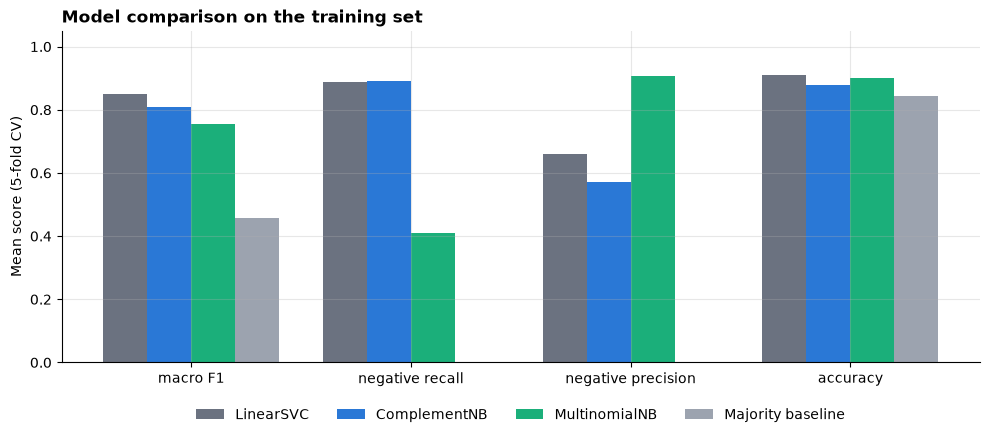

In [62]:
metrics_to_plot = ["macro F1", "negative recall", "negative precision", "accuracy"]
fig, ax = plt.subplots(figsize=(10, 4.5))
width = 0.8 / len(cv_mean)
x = np.arange(len(metrics_to_plot))
colors = {"LinearSVC": "#6b7280", "ComplementNB": BLUE, "MultinomialNB": "#1baf7a",
          "Majority baseline": GREY}
for i, (name, row) in enumerate(cv_mean.iterrows()):
    ax.bar(x + i * width - 0.4 + width / 2, row[metrics_to_plot], width=width,
           color=colors.get(name), label=name)
ax.set_xticks(x, metrics_to_plot)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Mean score (5-fold CV)")
ax.set_title("Model comparison on the training set", loc="left", fontweight="bold")
ax.legend(frameon=False, ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
fig.savefig(FIG_DIR / "03_model_comparison.png", dpi=150)
plt.show()

### 9.3 Best Naive Bayes model and final model

The project is built around Naive Bayes, so the better Naive Bayes variant is identified
explicitly. The final model is the one with the highest cross-validated macro F1 overall.

In [63]:
nb_scores = cv_mean.loc[["MultinomialNB", "ComplementNB"], "macro F1"]
BEST_NB = nb_scores.idxmax()
BEST_MODEL = cv_mean.drop(index="Majority baseline")["macro F1"].idxmax()

print(f"Best Naive Bayes variant: {BEST_NB} (macro F1 {nb_scores.max():.4f}, "
      f"{nb_scores.max() - nb_scores.min():+.4f} vs the other variant)")
print(f"Final model:              {BEST_MODEL} (macro F1 {cv_mean.loc[BEST_MODEL, 'macro F1']:.4f})")

Best Naive Bayes variant: ComplementNB (macro F1 0.8092, +0.0552 vs the other variant)
Final model:              LinearSVC (macro F1 0.8511)


## 10. Final model and test-set evaluation

TF-IDF and the classifier are combined in one scikit-learn `Pipeline`, fitted on the full training
set and evaluated once on the held-out test set. The best Naive Bayes variant is evaluated as well,
so the Naive Bayes result required by the project is reported on unseen data.

In [64]:
from sklearn.metrics import average_precision_score, classification_report, roc_auc_score
from sklearn.pipeline import Pipeline


def build_pipeline(model_name):
    return Pipeline([("tfidf", TfidfVectorizer(**TFIDF_PARAMS)), ("model", clone(MODELS[model_name]))])


def positive_score(pipeline, texts):
    model = pipeline.named_steps["model"]
    if hasattr(model, "predict_proba"):
        return pipeline.predict_proba(texts)[:, 1]
    return pipeline.decision_function(texts)


pipelines, test_rows = {}, []
for name in dict.fromkeys([BEST_MODEL, BEST_NB]):
    pipelines[name] = build_pipeline(name).fit(X_train, y_train)
    y_pred = pipelines[name].predict(X_test)
    score = positive_score(pipelines[name], X_test)
    test_rows.append({"model": name, **score_predictions(y_test, y_pred),
                      "ROC-AUC": roc_auc_score(y_test, score),
                      "PR-AUC (negative class)": average_precision_score(y_test == 0, -score)})

final_pipeline = pipelines[BEST_MODEL]
test_results = pd.DataFrame(test_rows).set_index("model")
test_results.round(4)

,macro F1,accuracy,balanced accuracy,negative precision,negative recall,negative F1,ROC-AUC,PR-AUC (negative class)
model,,,,,,,,
LinearSVC,0.8537,0.9121,0.9043,0.6633,0.8930,0.7612,0.9656,0.8698
ComplementNB,0.8085,0.8769,0.8826,0.5686,0.8909,0.6942,0.9515,0.8126


### 10.1 Classification report — final model

In [65]:
y_pred_test = final_pipeline.predict(X_test)
print(BEST_MODEL)
print(classification_report(y_test, y_pred_test, target_names=["Negative", "Positive"], digits=4))

LinearSVC
              precision    recall  f1-score   support

    Negative     0.6633    0.8930    0.7612     11414
    Positive     0.9787    0.9157    0.9461     61352

    accuracy                         0.9121     72766
   macro avg     0.8210    0.9043    0.8537     72766
weighted avg     0.9293    0.9121    0.9171     72766



### 10.2 Confusion matrices

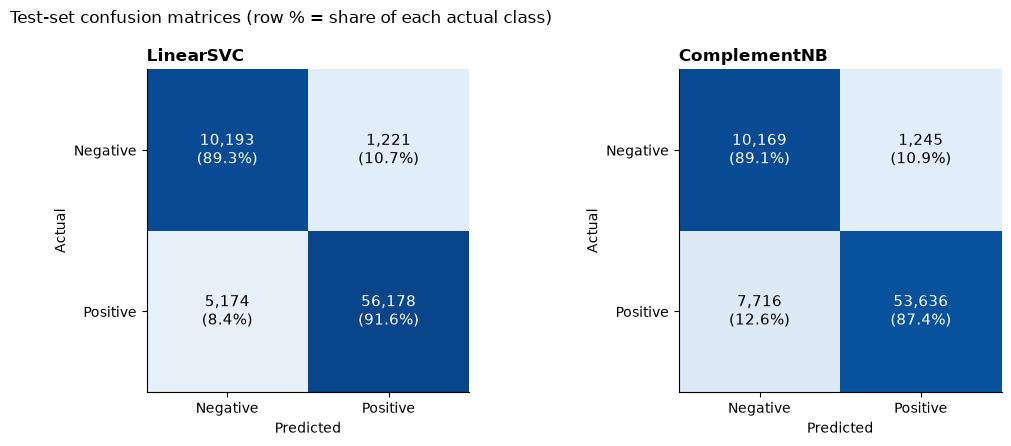

In [66]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, len(pipelines), figsize=(5.5 * len(pipelines), 4.5), squeeze=False)
for ax, (name, pipe) in zip(axes[0], pipelines.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    row_pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({row_pct[i, j]:.1f}%)", ha="center", va="center",
                    color="white" if row_pct[i, j] > 60 else "black", fontsize=11)
    ax.set_xticks([0, 1], ["Negative", "Positive"])
    ax.set_yticks([0, 1], ["Negative", "Positive"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.grid(False)
    ax.set_title(name, loc="left", fontweight="bold")
fig.suptitle("Test-set confusion matrices (row % = share of each actual class)", x=0.02, ha="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_confusion_matrices.png", dpi=150)
plt.show()

## 11. What the model learned

Each term's weight shows how strongly it pushes a review toward *Positive* (> 0) or *Negative*
(< 0). For the linear SVM this is the coefficient; for Naive Bayes it is the difference between the
two classes' log-probabilities of the term.

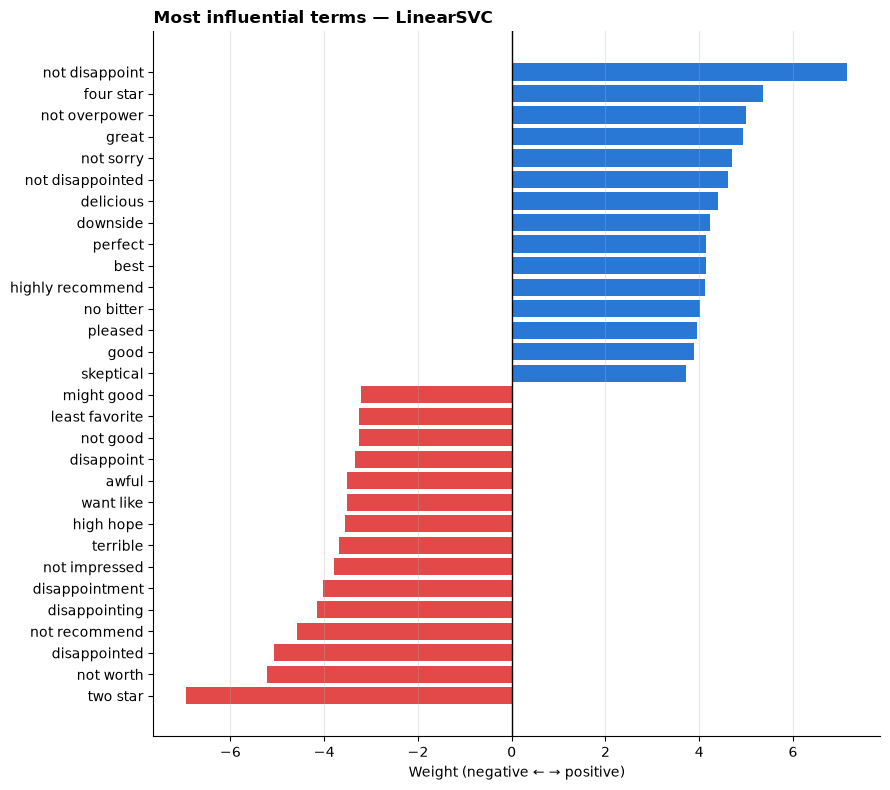

In [67]:
def term_weights(pipeline):
    model = pipeline.named_steps["model"]
    terms = pipeline.named_steps["tfidf"].get_feature_names_out()
    if hasattr(model, "coef_"):
        weights = model.coef_.ravel()
    else:
        weights = model.feature_log_prob_[1] - model.feature_log_prob_[0]
    return pd.Series(weights, index=terms).sort_values()


weights = term_weights(final_pipeline)
TOP_N = 15
top = pd.concat([weights.head(TOP_N), weights.tail(TOP_N)])

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(top.index, top.values, color=[RED if w < 0 else BLUE for w in top.values])
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Weight (negative ← → positive)")
ax.set_title(f"Most influential terms — {BEST_MODEL}", loc="left", fontweight="bold")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "05_top_terms.png", dpi=150)
plt.show()

### 11.1 Weights of negation phrases

The strongest negative and positive bigrams that start with a negation word.

In [68]:
neg_weights = weights[[t for t in weights.index if " " in t and t.split()[0] in NEGATIONS]]
toward_negative = neg_weights[neg_weights < 0].head(10)
toward_positive = neg_weights[neg_weights > 0].sort_values(ascending=False).head(10)
pd.concat({
    "pushes toward Negative": toward_negative.round(3).rename_axis("term").reset_index(name="weight"),
    "pushes toward Positive": toward_positive.round(3).rename_axis("term").reset_index(name="weight"),
}, axis=1)

pushes toward Negative        pushes toward Positive       
                    term weight                   term weight
0              not worth -5.211         not disappoint  7.152
1          not recommend -4.569          not overpower  5.001
2          not impressed -3.791              not sorry  4.694
3               not good -3.266       not disappointed  4.603
4              not tasty -3.097              no bitter  4.011
5              not happy -3.076             not bitter  3.582
6               not work -2.997                no mess  3.580
7              not great -2.897             not regret  3.560
8            not pleased -2.850              not salty  3.420
9           not pleasant -2.725          no aftertaste  3.314

## 12. Error analysis

The test reviews the final model got wrong with the highest confidence. Reading them shows the
limits of a bag-of-words model and of star ratings as labels.

In [69]:
test_view = df.loc[X_test.index, ["Score", "Text"]].assign(
    actual=y_test.map(LABEL_NAMES), predicted=pd.Series(y_pred_test, index=X_test.index).map(LABEL_NAMES),
    score=positive_score(final_pipeline, X_test))
errors = test_view[test_view["actual"] != test_view["predicted"]]

print(f"Misclassified test reviews: {len(errors):,} of {len(test_view):,} "
      f"({len(errors) / len(test_view) * 100:.2f}%)")
display(errors["actual"].value_counts().rename("errors by actual class").to_frame().T)

cases = {
    "Actual Negative, predicted Positive with the highest confidence":
        errors.sort_values("score", ascending=False).head(5),
    "Actual Positive, predicted Negative with the highest confidence":
        errors.sort_values("score").head(5),
}
with pd.option_context("display.max_colwidth", 220):
    for title, rows in cases.items():
        print(f"\n{title}")
        display(rows.assign(Text=rows["Text"].str[:220], score=rows["score"].round(3))
                [["Score", "score", "Text"]].rename(columns={"Score": "stars", "score": "model score"}))

Misclassified test reviews: 6,395 of 72,766 (8.79%)


actual,Positive,Negative
errors by actual class,5174,1221



Actual Negative, predicted Positive with the highest confidence


,stars,model score,Text
45273,1,3.989,"Perfect...just a little something sweet to keep you going...no aftertaste of any kind. (Because of the reviews, just ordered the berry and orange...can't wait to try those, too.) Great tasting sugar free candy is n..."
144498,1,2.976,A little too sweet for us. However we had no problem swapping it to a friend for some coffee we enjoyed much more. She actually loves the Mocha blend and drinks it frequently.<br />We were glad to have the ability to...
280890,2,2.892,"Your service is the best. My package arrived promptly, and very well packaged -- it was glass -- very important. And the product is exactly as advertized -- I'd just got back from Paris and fell in love with their ..."
34887,2,2.528,These flavors are so subtle (I ate a whole one before I gave to my kids!) but so great to have your tot introduced to such healthy veggies!<br />I've added about half to jarred organic pasta sauce and it gave it a sw...
247316,1,2.441,"Pleasant, no caffeine tea.<br />Good to drink in the afternoon.<br />Much more pleasant, than chamomile.<br />Not available with Meijer Store any more..."



Actual Positive, predicted Negative with the highest confidence


,stars,model score,Text
331428,4,-3.343,"Are you joking about the price? You can get this at Fairway, wholeFoods, and other health stores for under $5 bucks. So what's the deal with this exorbitant price. It's flat out ridiculous. Iwouldn't purchase it he..."
363741,5,-3.173,"Ordered coffee for a few months. Now I would not recommend it to my worst enemy. The coffee now has no aroma, is light brown and taste worse than ___________. (fill in the blank)"
40524,4,-3.084,I have ordered this exact item from Amazon a few times before. It is basically two 12 packs in one box. One of the 12 packs was already opened and was missing four of the mini bottles. This is the first time I have h...
53180,4,-2.896,"At first sip I did not like the taste. It was a bit weak and I didn't think I would like it. It just wasn't the taste I expected....a little bland, almost watery. I did not get the"
15631,5,-2.780,You can buy this at the pet store for about 2.19 a can . on the web here this is a rip. Sorry


## 13. Predictions on new reviews

New text goes through exactly the same pre-processing (`preprocess_batch`) before the fitted
pipeline. The model was trained on Positive vs Negative only, so a neutral review is still forced
into one of the two classes.

In [70]:
def predict_sentiment(texts):
    clean = preprocess_batch(texts)
    labels = final_pipeline.predict(clean)
    return pd.DataFrame({"review": texts, "pre-processed": clean,
                         "sentiment": [LABEL_NAMES[int(l)] for l in labels],
                         "score": positive_score(final_pipeline, clean).round(3)})


new_reviews = [
    "This coffee is absolutely delicious, I will definitely buy it again!",
    "I am not happy with this product. The taste was terrible and it arrived stale.",
    "Not bad at all, my kids love these snacks.",
    "The package arrived damaged and half of the cookies were broken.",
    "Great price, but my dog would not eat it.",
]
with pd.option_context("display.max_colwidth", 90):
    display(predict_sentiment(new_reviews))

,review,pre-processed,sentiment,score
0,"This coffee is absolutely delicious, I will definitely buy it again!",coffee absolutely delicious definitely buy,Positive,3.970
1,I am not happy with this product. The taste was terrible and it arrived stale.,not happy product taste terrible arrive stale,Negative,-2.921
2,"Not bad at all, my kids love these snacks.",not bad kid love snack,Positive,1.567
3,The package arrived damaged and half of the cookies were broken.,package arrive damage half cooky break,Negative,-0.904
4,"Great price, but my dog would not eat it.",great price dog would not eat,Positive,0.184


## 14. Save the model and metrics



In [71]:
model_path = MODEL_DIR / "sentiment_pipeline.joblib"
joblib.dump(final_pipeline, model_path, compress=3)

metrics = {
    "dataset": {"raw_reviews": int(len(raw)), "modelling_reviews": int(len(df)),
                "negative": int((df["label"] == 0).sum()), "positive": int((df["label"] == 1).sum()),
                "train": int(len(X_train)), "test": int(len(X_test))},
    "tfidf": {"ngram_range": [1, 2], "max_features": 10_000, "min_df": 2,
              "features": int(len(vocab)), "negation_bigrams": int(len(negation_terms))},
    "cross_validation_mean": cv_mean.round(4).to_dict(orient="index"),
    "final_model": BEST_MODEL,
    "best_naive_bayes": BEST_NB,
    "test": test_results.round(4).to_dict(orient="index"),
}
(ROOT / "reports" / "metrics.json").write_text(json.dumps(metrics, indent=2))

print(f"Saved {model_path.relative_to(ROOT)} ({model_path.stat().st_size / 1024**2:.1f} MB)")
print("Saved reports/metrics.json")

Saved models\sentiment_pipeline.joblib (0.2 MB)
Saved reports/metrics.json


## 15. Summary

In [72]:
summary = pd.Series({
    "Reviews used for modelling": f"{len(df):,}",
    "Negative / Positive": f"{class_share[0]:.1f}% / {class_share[1]:.1f}%",
    "TF-IDF features (uni + bigrams)": f"{len(vocab):,}",
    "Negation bigrams in vocabulary": f"{len(negation_terms):,}",
    "Final model": BEST_MODEL,
    "Test macro F1": f"{test_results.loc[BEST_MODEL, 'macro F1']:.4f}",
    "Test accuracy": f"{test_results.loc[BEST_MODEL, 'accuracy']:.4f}",
    "Test negative recall": f"{test_results.loc[BEST_MODEL, 'negative recall']:.4f}",
    "Best Naive Bayes": BEST_NB,
    "Naive Bayes test macro F1": f"{test_results.loc[BEST_NB, 'macro F1']:.4f}",
}, name="")
summary.to_frame()

,
Reviews used for modelling,"363,829"
Negative / Positive,15.7% / 84.3%
TF-IDF features (uni + bigrams),"10,000"
Negation bigrams in vocabulary,336
Final model,LinearSVC
Test macro F1,0.8537
Test accuracy,0.9121
Test negative recall,0.8930
Best Naive Bayes,ComplementNB
Naive Bayes test macro F1,0.8085
